<a href="https://colab.research.google.com/github/11531055-wei/asteroid-data-analysis/blob/main/%E8%87%AA%E4%B8%BB%E5%AD%B8%E7%BF%92%E5%B0%88%E6%A1%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#第一週10/23
name=input("小行星名字:")
dist=float(input("請輸入近地距離(Au):)"))
H=float(input("請輸入絕對星等(H):"))

is_big=H<=22.0
is_close=dist<=0.05
is_PHA=is_big and is_close#潛在威脅小行星(PHA)

print(f"\n--- 天體分析報告：{name} ---")
print("近地距離:",dist)
print("絕對星等:",H)

if H==0.2 and dist==0.002:
  print("這是月球")
elif is_PHA:
  print("警告!",name,"是具威脅性的小行星")
else:
  print(name,"不是具威脅性的小行星")

小行星名字:月球
請輸入近地距離(Au):)0.002
請輸入絕對星等(H):0.2

--- 天體分析報告：月球 ---
近地距離: 0.002
絕對星等: 0.2
這是月球


In [ ]:
#第二週11/1  part_2
#準備文字資料
csv_content = """name,distance,h_magnitude
Apophis,0.031,19.7
Ceres,2.770,3.3
"""

# 2. 把這些文字寫入一個名為 "asteroids.csv" 的檔案裡
with open("asteroids.csv", "w", encoding="utf-8") as file:
    file.write(csv_content)

print("ok")

ok


In [ ]:
#第二週11/1  part_1結合part_2
import csv

def is_hazardous(dist,H,max_dist=0.05,max_H=22.0):
  return(dist<=max_dist) and (H<=max_H)

def generate_report(name,dist,H):
  hazard_flag=is_hazardous(dist,H)
  status="警告，這是具威脅性的天體" if hazard_flag else "安全，這不是具威脅性的天體"
  print(f"[{name}] 距離:{dist:.3f} AU | 星等:{H:.1f} -> {status}")

print("=== 開始從 asteroids.csv 讀取資料 ===\n")

with open("asteroids.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file)
    header = next(reader)
    for row in reader:
      t_name=row[0]
      t_dist=float(row[1])
      t_H=float(row[2])
      generate_report(t_name,t_dist,t_H)

=== 開始從 asteroids.csv 讀取資料 ===

[Apophis] 距離:0.031 AU | 星等:19.7 -> 警告，這是具威脅性的天體
[Ceres] 距離:2.770 AU | 星等:3.3 -> 安全，這不是具威脅性的天體


===天文資料庫===
       discovery_year  distance_au      h_mag  diameter_km
count       10.000000    10.000000  10.000000     9.000000
mean      1960.600000     0.425500  17.080000   164.830333
std         90.771018     0.894232   7.838764   338.060820
min       1801.000000     0.002000   3.300000     0.003000
25%       1923.250000     0.006000  12.950000     0.050000
50%       2001.500000     0.039500  19.500000     0.490000
75%       2023.750000     0.135750  22.550000    16.840000
max       2026.000000     2.770000  25.500000   939.400000


===檢查欄位缺失數量 ===
designation       0
discovery_year    0
distance_au       0
h_mag             0
diameter_km       1
dtype: int64


填補完成！預設平均直徑為:164.830 km
===整理後的資料庫 (空缺已被填補) ===
    designation  discovery_year  distance_au  h_mag  diameter_km
0      2024 BX1            2024        0.002   25.5     0.003000
1       Apophis            2004        0.031   19.7     0.370000
2         Ceres            1801        2.770    3.3   939.400000
3          Eros 

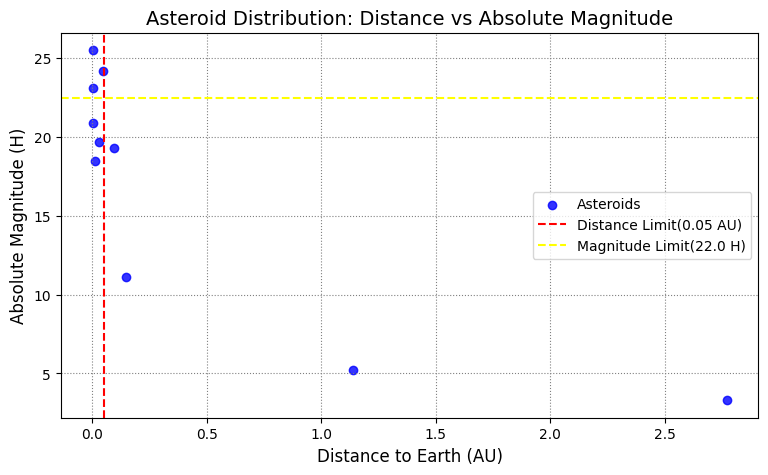

In [ ]:
#第三週11/8
import pandas as pd
import io
#匯入資料
csv_data="""designation,discovery_year,distance_au,h_mag,diameter_km
2024 BX1,2024,0.002,25.5,0.003
Apophis,2004,0.031,19.7,0.370
Ceres,1801,2.770,3.3,939.400
Eros,1898,0.149,11.1,16.840
Bennu,1999,0.003,20.9,0.490
Ryugu,1999,0.096,19.3,0.900
2023 DW,2023,0.048,24.2,0.050
Vesta,1807,1.140,5.2,525.400
MyAsteroid_A,2025,0.012,18.5,
MyAsteroid_B,2026,0.004,23.1,0.020
"""
df=pd.read_csv(io.StringIO(csv_data))

print("===天文資料庫===")
print(df.describe())
print("\n"+"="*50+"\n")

print("===檢查欄位缺失數量 ===")
print(df.isna().sum())
print("\n"+"="*50+"\n")

df_cleaned=df.copy()
#檢查完缺失資料之後才能打填補程式
mean_diameter=df_cleaned["diameter_km"].mean()#變數中的那項資料
df_cleaned["diameter_km"]=df["diameter_km"].fillna(mean_diameter)

print(f"填補完成！預設平均直徑為:{mean_diameter:.3f} km")
print("===整理後的資料庫 (空缺已被填補) ===")
print(df_cleaned)

import matplotlib.pyplot as plt
plt.figure(figsize=(9,5))

plt.scatter(df_cleaned["distance_au"], df_cleaned["h_mag"],color="blue",alpha=0.8,label="Asteroids")

plt.axvline(x=0.05,color="red",linestyle="--",label="Distance Limit(0.05 AU)")
plt.axhline(y=22.5,color="yellow",linestyle="--",label="Magnitude Limit(22.0 H)")

plt.title("Asteroid Distribution: Distance vs Absolute Magnitude",fontsize=14)
plt.xlabel("Distance to Earth (AU)",fontsize=12)
plt.ylabel("Absolute Magnitude (H)",fontsize=12)
plt.grid(True,linestyle=":",color="gray")
plt.legend()

plt.show()

===天文資料庫===
     designation orbit_class  discovery_year  distance_au  h_mag  diameter_km
0        1 Ceres   Main Belt            1801         2.77   3.34       939.40
1        4 Vesta   Main Belt            1807         2.36   3.20       525.40
2       433 Eros         NEA            1898         1.46  11.16        16.84
3    1566 Icarus         NEA            1949         1.08  16.90         1.00
4     624 Hektor      Trojan            1907         5.24   7.49       225.00
5  911 Agamemnon      Trojan            1919         5.26   7.89       167.00
6   1036 Ganymed         NEA            1924         2.66   9.45        37.67
7    2060 Chiron     Centaur            1977        13.70   6.10       218.00
8   588 Achilles      Trojan            1906         5.19   8.60       135.50
9       2 Pallas   Main Belt            1802         2.77   4.13       512.00



===檢查缺失欄位===

designation       0
orbit_class       0
discovery_year    0
distance_au       0
h_mag             0
diameter_km  

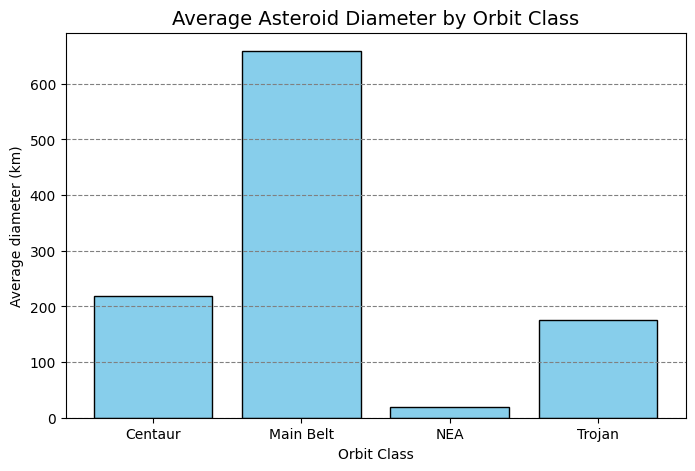

In [33]:
#第四週11/11
import pandas as pd
import io
import matplotlib.pyplot as plt
csv_data="""designation,orbit_class,discovery_year,distance_au,h_mag,diameter_km
1 Ceres,Main Belt,1801,2.77,3.34,939.4
4 Vesta,Main Belt,1807,2.36,3.20,525.4
433 Eros,NEA,1898,1.46,11.16,16.84
1566 Icarus,NEA,1949,1.08,16.90,1.00
624 Hektor,Trojan,1907,5.24,7.49,225.0
911 Agamemnon,Trojan,1919,5.26,7.89,167.0
1036 Ganymed,NEA,1924,2.66,9.45,37.67
2060 Chiron,Centaur,1977,13.70,6.10,218.0
588 Achilles,Trojan,1906,5.19,8.60,135.5
2 Pallas,Main Belt,1802,2.77,4.13,512.0
"""
df=pd.read_csv(io.StringIO(csv_data))
print("===天文資料庫===")
print(df)
print("\n"+"="*50+"\n")

print("\n"+"===檢查缺失欄位==="+"\n")
print(df.isna().sum())
print("\n"+"="*50+"\n")

grouped_diameter=df.groupby("orbit_class")["diameter_km"].mean().round(2)

plt.figure(figsize=(8,5))
plt.bar(grouped_diameter.index,grouped_diameter.values,color="skyblue",edgecolor="black")

plt.title("Average Asteroid Diameter by Orbit Class",fontsize=14)
plt.xlabel("Orbit Class")
plt.ylabel("Average diameter (km)")
plt.grid(axis="y",linestyle="--",color="gray")

plt.show()


---各軌道類別統計表---
  orbit_class  Count  Mean_Diameter_km  Max_Diameter_km  Mean_Distance_AU
0     Centaur      1            218.00           218.00             13.70
1   Main Belt      3            658.93           939.40              2.63
2         NEA      3             18.50            37.67              1.73
3      Trojan      3            175.83           225.00              5.23


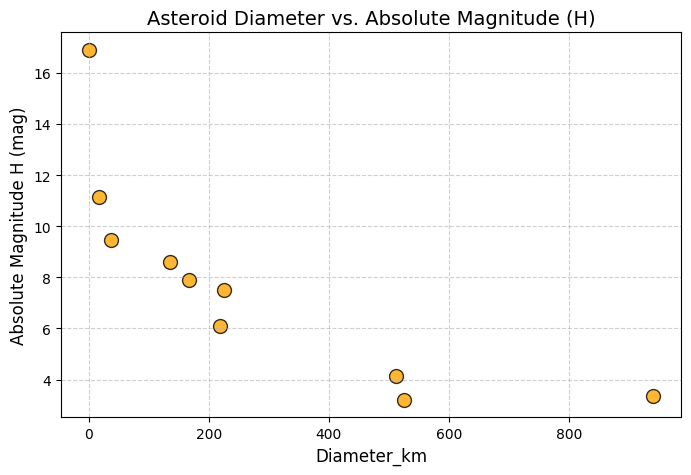

In [43]:
#第五週11/21
summary_table=df.groupby("orbit_class").agg(
    Count=("designation","count"),
    Mean_Diameter_km=("diameter_km","mean"),
    Max_Diameter_km=("diameter_km","max"),
    Mean_Distance_AU=("distance_au","mean")
).round(2).reset_index()
print("---各軌道類別統計表---")
print(summary_table)

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(
  df["diameter_km"],
  df["h_mag"],
  color="orange",
  edgecolors="black",
  s=100,
  alpha=0.8
)
plt.title("Asteroid Diameter vs. Absolute Magnitude (H)", fontsize=14)
plt.xlabel("Diameter_km",fontsize=12)
plt.ylabel("Absolute Magnitude H (mag)",fontsize=12)
plt.grid(True,linestyle="--",alpha=0.6)
plt.show()

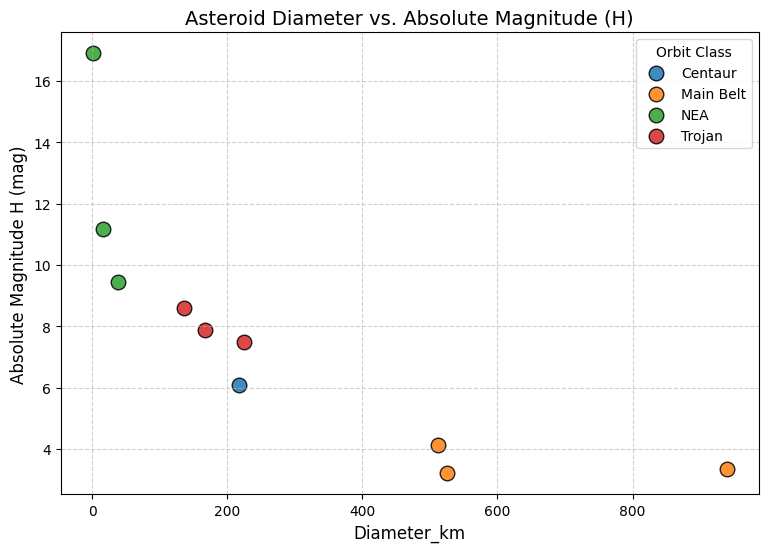

In [53]:
plt.figure(figsize=(9,6))
for orbit_name,group_data in df.groupby("orbit_class"):
  plt.scatter(
      group_data["diameter_km"],
      group_data["h_mag"],
      label=orbit_name,#給圖例命名
      s=110,
      alpha=0.85,
      edgecolors="black"
  )
plt.title("Asteroid Diameter vs. Absolute Magnitude (H)", fontsize=14)
plt.xlabel("Diameter_km",fontsize=12)
plt.ylabel("Absolute Magnitude H (mag)",fontsize=12)
plt.grid(True,linestyle="--",alpha=0.6)
plt.legend(title="Orbit Class",fontsize=10)
#plt.xscale("log")#拉直
plt.show()

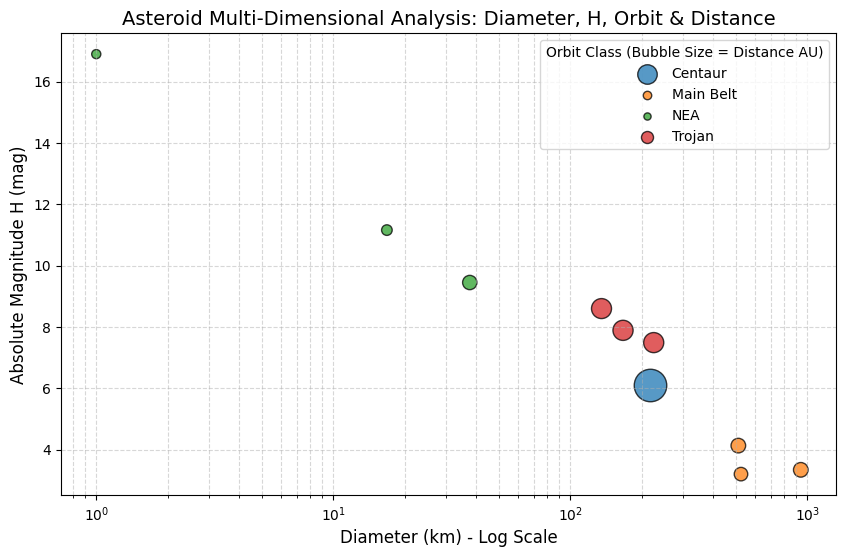

In [70]:
plt.figure(figsize=(10,6))
for orbit_name,group_data in df.groupby("orbit_class"):
  plt.scatter(
      group_data["diameter_km"],
      group_data["h_mag"],
      s=group_data["distance_au"]*40,
      label=orbit_name,
      alpha=0.75,
      edgecolors="black"
      #linewidth=1.2
  )
plt.title("Asteroid Multi-Dimensional Analysis: Diameter, H, Orbit & Distance", fontsize=14)
plt.xlabel("Diameter (km) - Log Scale", fontsize=12)
plt.ylabel("Absolute Magnitude H (mag)", fontsize=12)
plt.legend(title="Orbit Class (Bubble Size = Distance AU)", fontsize=10, markerscale=0.6)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.xscale("log")
plt.show()

In [64]:
#程式模組化1  寫入資料
def get_data():
  import pandas as pd
  import io
  import matplotlib.pyplot as plt
  csv_data="""designation,orbit_class,discovery_year,distance_au,h_mag,diameter_km
  1 Ceres,Main Belt,1801,2.77,3.34,939.4
  4 Vesta,Main Belt,1807,2.36,3.20,525.4
  433 Eros,NEA,1898,1.46,11.16,16.84
  1566 Icarus,NEA,1949,1.08,16.90,1.00
  624 Hektor,Trojan,1907,5.24,7.49,225.0
  911 Agamemnon,Trojan,1919,5.26,7.89,167.0
  1036 Ganymed,NEA,1924,2.66,9.45,37.67
  2060 Chiron,Centaur,1977,13.70,6.10,218.0
  588 Achilles,Trojan,1906,5.19,8.60,135.5
  2 Pallas,Main Belt,1802,2.77,4.13,512.0
  """
  df=pd.read_csv(io.StringIO(csv_data))
  print("===天文資料庫===")
  print(df)
  print("\n"+"="*50+"\n")

get_data()

===天文資料庫===
       designation orbit_class  discovery_year  distance_au  h_mag  \
0          1 Ceres   Main Belt            1801         2.77   3.34   
1          4 Vesta   Main Belt            1807         2.36   3.20   
2         433 Eros         NEA            1898         1.46  11.16   
3      1566 Icarus         NEA            1949         1.08  16.90   
4       624 Hektor      Trojan            1907         5.24   7.49   
5    911 Agamemnon      Trojan            1919         5.26   7.89   
6     1036 Ganymed         NEA            1924         2.66   9.45   
7      2060 Chiron     Centaur            1977        13.70   6.10   
8     588 Achilles      Trojan            1906         5.19   8.60   
9         2 Pallas   Main Belt            1802         2.77   4.13   

   diameter_km  
0       939.40  
1       525.40  
2        16.84  
3         1.00  
4       225.00  
5       167.00  
6        37.67  
7       218.00  
8       135.50  
9       512.00  




In [66]:
#程式模組化2  查缺
def clean_data(df):
  print("\n"+"===檢查缺失欄位==="+"\n")
  print(df.isna().sum())
  print("\n"+"="*50+"\n")

clean_data(df)


===檢查缺失欄位===

designation       0
orbit_class       0
discovery_year    0
distance_au       0
h_mag             0
diameter_km       0
dtype: int64




In [69]:
#程式模組化3  填補
def fill_missing(df):
  df_cleaned=df.copy()
  mean_diameter=df_cleaned["diameter_km"].mean()#變數中的那項資料   #
  df_cleaned["diameter_km"]=df["diameter_km"].fillna(mean_diameter)  #

  print(f"填補完成！預設平均直徑為:{mean_diameter:.3f} km")     #
  print("===整理後的資料庫 (空缺已被填補) ===")
  print(df_cleaned)

In [62]:
#程式模組化4  統計資料
def show_summary(df):
  summary_table=df.groupby("orbit_class").agg(
    Count=("designation","count"),
    Mean_Diameter_km=("diameter_km","mean"),
    Max_Diameter_km=("diameter_km","max"),
    Mean_Distance_AU=("distance_au","mean")
  ).round(2).reset_index()
  print("---各軌道類別統計表---")
  print(summary_table)

show_summary(df)

---各軌道類別統計表---
  orbit_class  Count  Mean_Diameter_km  Max_Diameter_km  Mean_Distance_AU
0     Centaur      1            218.00           218.00             13.70
1   Main Belt      3            658.93           939.40              2.63
2         NEA      3             18.50            37.67              1.73
3      Trojan      3            175.83           225.00              5.23


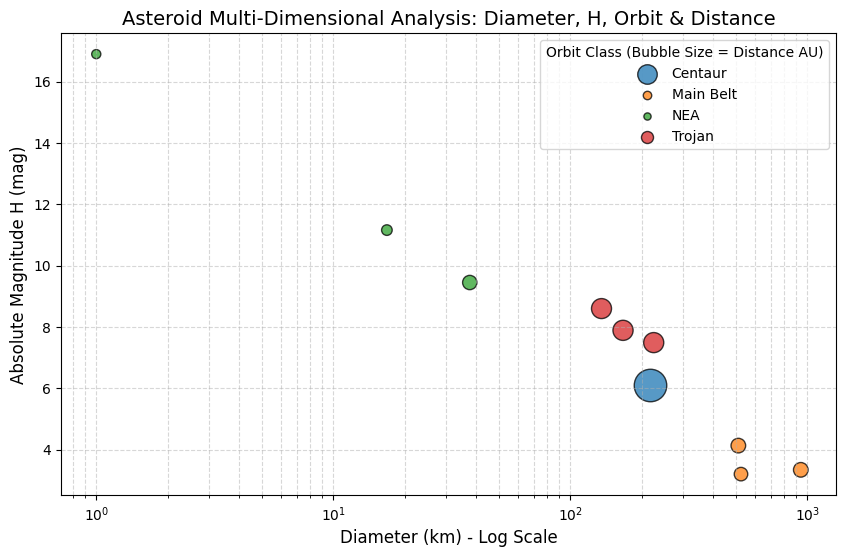

In [58]:
#程式模組化5  圖表化
def plot_bubble_chart(df):
  plt.figure(figsize=(10,6))
  for orbit_name,group_data in df.groupby("orbit_class"):
    plt.scatter(
       group_data["diameter_km"],
        group_data["h_mag"],
        s=group_data["distance_au"]*40,
        label=orbit_name,
        alpha=0.75,
        edgecolors="black"
       #linewidth=1.2
    )
  plt.title("Asteroid Multi-Dimensional Analysis: Diameter, H, Orbit & Distance", fontsize=14)
  plt.xlabel("Diameter (km) - Log Scale", fontsize=12)
  plt.ylabel("Absolute Magnitude H (mag)", fontsize=12)
  plt.legend(title="Orbit Class (Bubble Size = Distance AU)", fontsize=10, markerscale=0.6)
  plt.grid(True, which="both", linestyle="--", alpha=0.5)
  plt.xscale("log")
  plt.show()

plot_bubble_chart(df)